# Experiments on What the Root Causes of Flow time is.

Sample run of the main policy (Year 3, heijunka release, staggered workcell setups, SPC scrap at 25%), with **breakdowns and planned maintenance turned off** (`failures_on=False`, `pm_on=False`). Everything else matches `heijunka_simulation.ipynb`, so the spikes left in the chart are caused by something other than maintenance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS
from lcd_sim.stats import run
from lcd_sim import plots as P

YEAR = 3
base = dict(release_mode="heijunka", setup_scope="workcell", scrap_scale=0.25)
sc = get_scenario(YEAR, **base, failures_on=False, pm_on=False)
res = run(sc)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement; seed {sc.seed}")

Year 3; 2-week warm-up; 8-week measurement; seed 1


## Flow time SPC chart

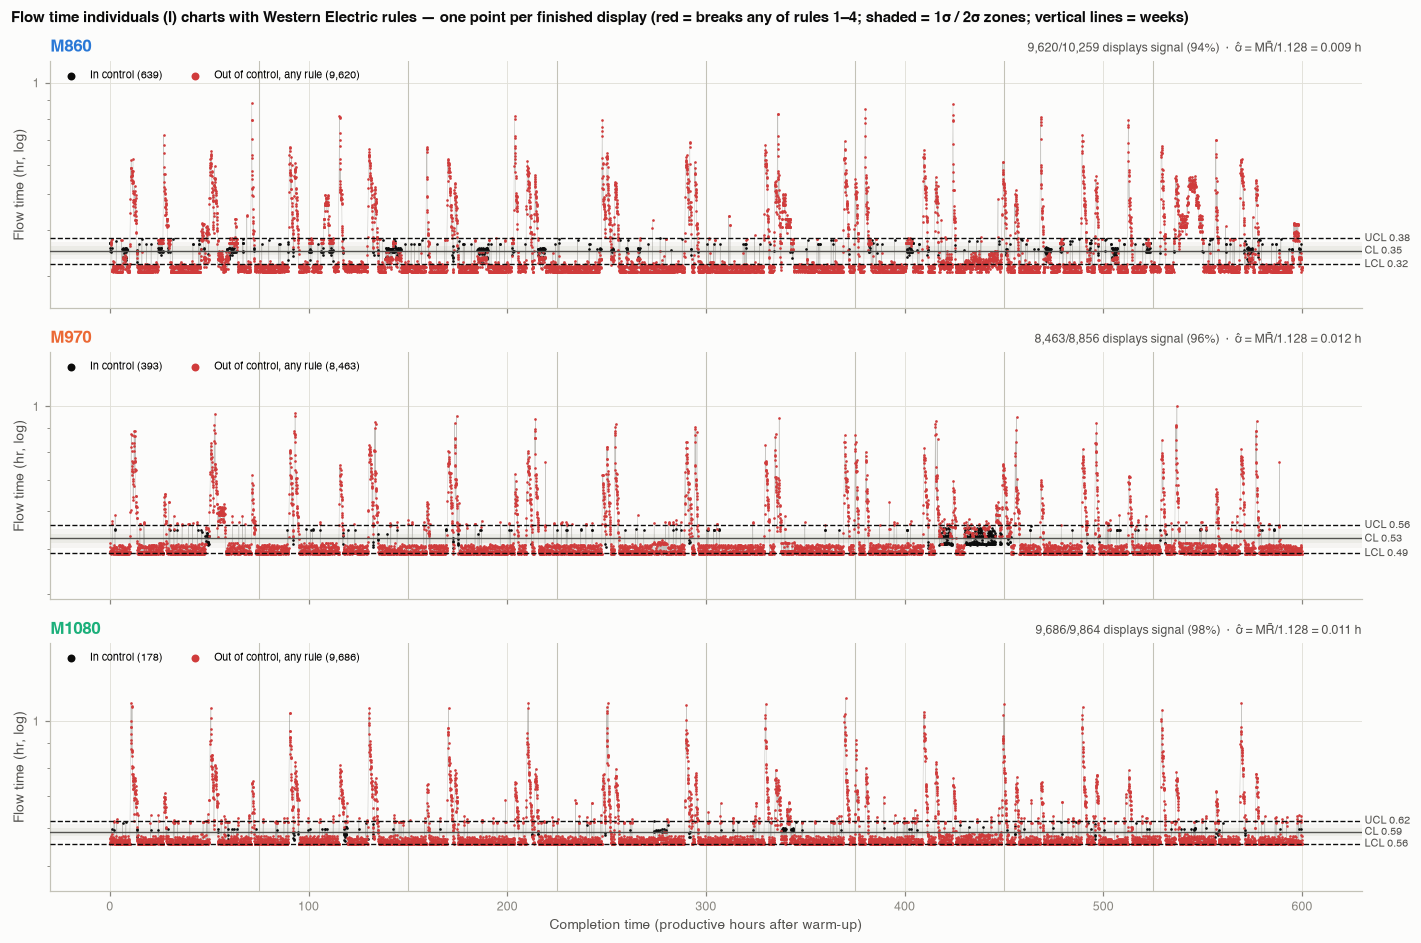

In [2]:
P.plot_flow_time_spc(res); plt.show()

## Flow time by model

In [3]:
spc = P.flow_time_spc(res)
rule_cols = [f"Rule {r}" for r in P.WE_RULES]
display(spc.groupby("Model", sort=False)
           .agg(Displays=("Part", "count"), **{"CL (hr)": ("CL", "first"), "σ̂ = MR̄/1.128 (hr)": ("sigma", "first"),
                "UCL (hr)": ("+3σ", "first"), "LCL (hr)": ("-3σ", "first")},
                **{c: (c, "sum") for c in rule_cols}, **{"Any signal": ("Signal", "sum")})
           .reindex(MODELS))
ft = res.flow.groupby("Model")["Flow time (hr)"].describe(percentiles=[.5, .9, .99]).reindex(MODELS)
display(ft.round(3))

,Displays,CL (hr),σ̂ = MR̄/1.128 (hr),UCL (hr),LCL (hr),Rule 1,Rule 2,Rule 3,Rule 4,Any signal
Model,,,,,,,,,,
M860,10259,0.351675,0.009442,0.380000,0.323350,8182,8782,9357,9058,9620
M970,8856,0.525280,0.011942,0.561107,0.489454,3189,6508,8100,8170,8463
M1080,9864,0.589723,0.010760,0.622002,0.557444,3072,7954,9224,9090,9686


,count,mean,std,min,50%,90%,99%,max
Model,,,,,,,,
M860,10259.0,0.352,0.075,0.307,0.318,0.467,0.631,0.882
M970,8856.0,0.525,0.072,0.488,0.495,0.615,0.821,1.003
M1080,9864.0,0.590,0.072,0.557,0.561,0.676,0.915,1.116


## Compared with maintenance on (seeds 1–3)

In [4]:
# rows = []
# for label, kw in {"Maintenance on": {}, "No maintenance": dict(failures_on=False, pm_on=False)}.items():
#     for seed in (1, 2, 3):
#         r = run(get_scenario(YEAR, **base, **kw, seed=seed, keep_logs=False))
#         f = r.flow["Flow time (hr)"]
#         rows.append({"Case": label, "Seed": seed, "Throughput/wk": r.kpis["Throughput|Total per week"],
#                      "Avg flow (hr)": f.mean(), "P90 flow (hr)": f.quantile(.9), "Max flow (hr)": f.max(),
#                      "Avg WIP": r.kpis["WIP|Average WIP (parts)"]})
# cmp = pd.DataFrame(rows)
# display(cmp.groupby("Case").mean(numeric_only=True).drop(columns="Seed").round(2))

# Extension: no changeover time

Two more what-ifs with **changeover (setup) time set to zero at every station** (`setups_on=False`). Everything else is the same as above.

1. No changeover time, **maintenance on** (breakdowns + planned maintenance as in the base model)
2. No changeover time, **no maintenance**

In [5]:
def flow_summary(r):
    return (r.flow.groupby("Model")["Flow time (hr)"]
             .describe(percentiles=[.5, .9, .99]).reindex(MODELS).round(3))

res_nosetup = run(get_scenario(YEAR, **base, setups_on=False))
res_nosetup_nomaint = run(get_scenario(YEAR, **base, setups_on=False, failures_on=False, pm_on=False))

## 1) No changeover time, maintenance on

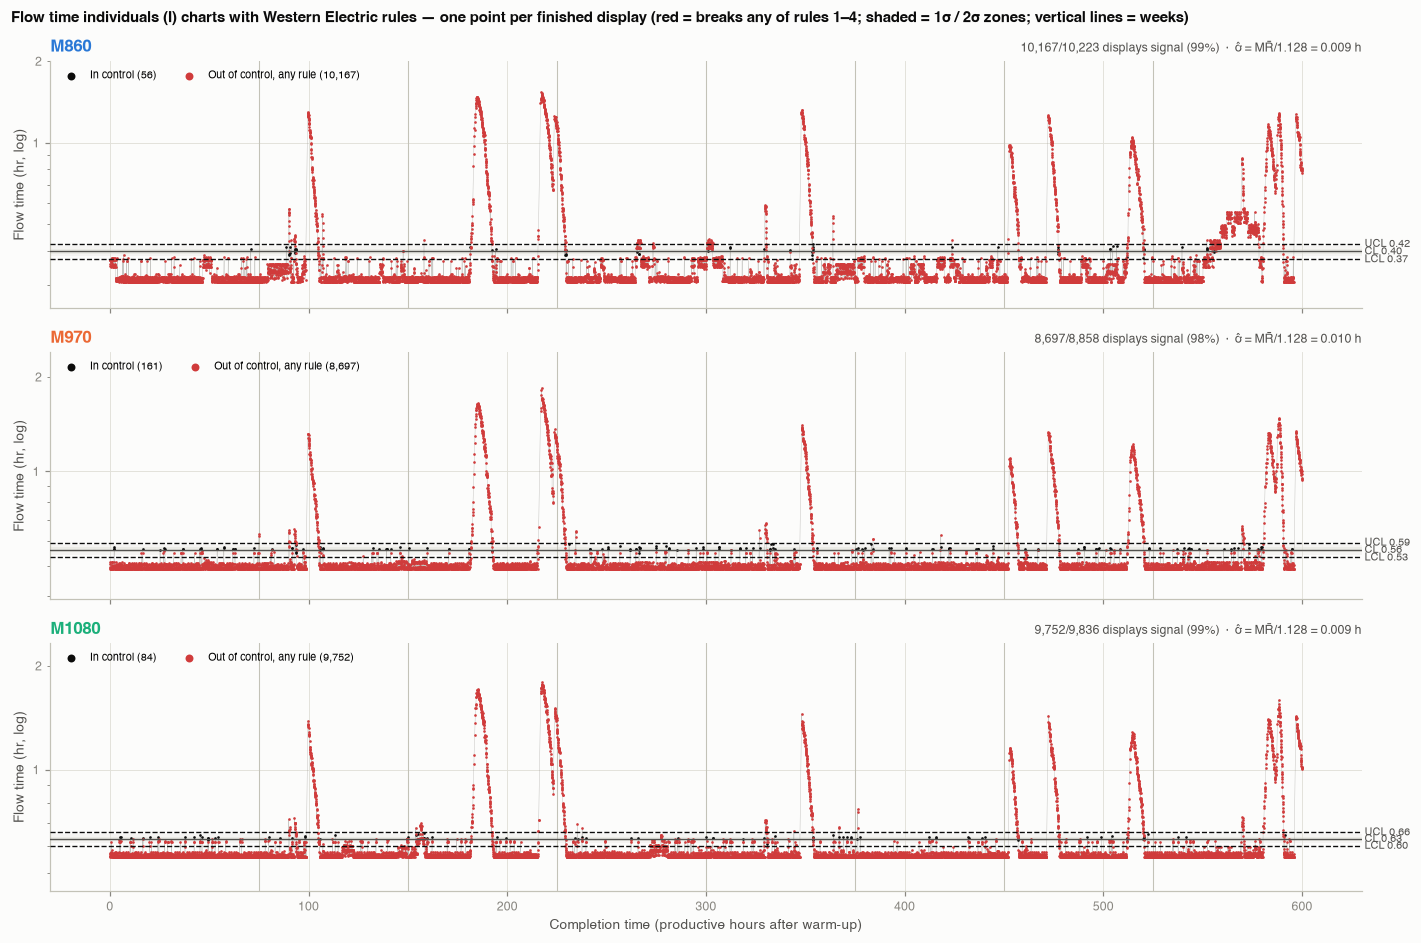

,count,mean,std,min,50%,90%,99%,max
Model,,,,,,,,
M860,10223.0,0.398,0.208,0.307,0.318,0.573,1.289,1.543
M970,8858.0,0.562,0.197,0.488,0.494,0.715,1.434,1.848
M1080,9836.0,0.629,0.196,0.557,0.561,0.771,1.511,1.791


In [6]:
P.plot_flow_time_spc(res_nosetup); plt.show()
display(flow_summary(res_nosetup))

## 2) No changeover time, no maintenance

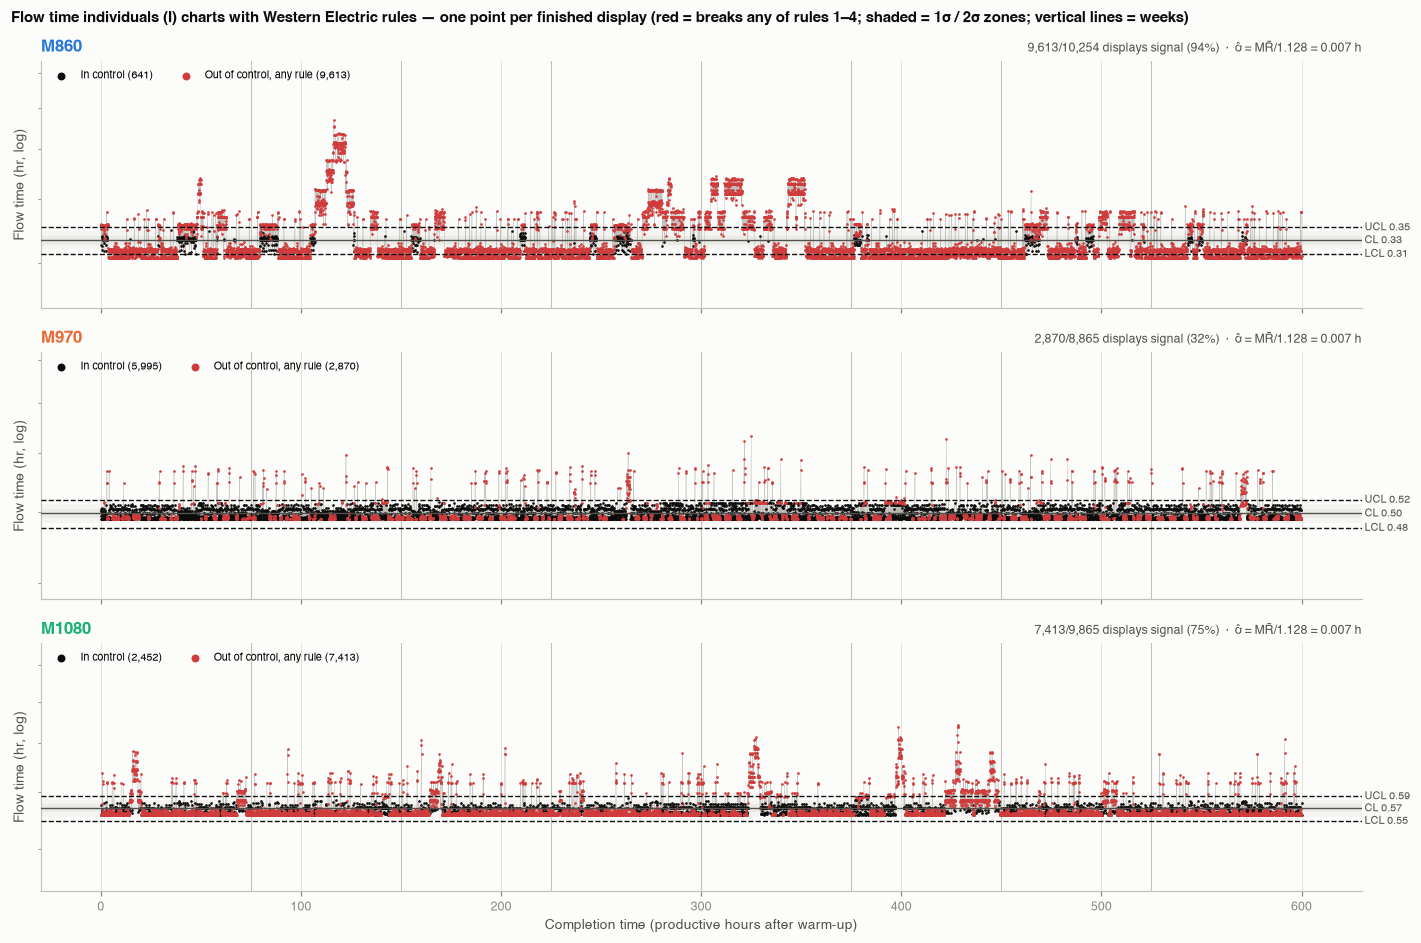

,count,mean,std,min,50%,90%,99%,max
Model,,,,,,,,
M860,10254.0,0.333,0.036,0.307,0.317,0.376,0.475,0.569
M970,8865.0,0.497,0.014,0.488,0.492,0.510,0.567,0.632
M1080,9865.0,0.569,0.022,0.557,0.561,0.595,0.667,0.742


In [7]:
P.plot_flow_time_spc(res_nosetup_nomaint); plt.show()
display(flow_summary(res_nosetup_nomaint))

## All cases (seeds 1–3)

In [8]:
res_clean = run(get_scenario(YEAR, **{**base, "scrap_scale": 0}, setups_on=False, failures_on=False, pm_on=False))
res_noscrap = run(get_scenario(YEAR, **{**base, "scrap_scale": 0}))

## 3) No scrap, no maintenance, no changeover time

,count,mean,std,min,50%,90%,99%,max
Model,,,,,,,,
M860,10255.0,0.313,0.004,0.307,0.314,0.315,0.329,0.333
M970,8868.0,0.491,0.005,0.488,0.490,0.498,0.520,0.520
M1080,9851.0,0.560,0.006,0.557,0.557,0.572,0.583,0.583


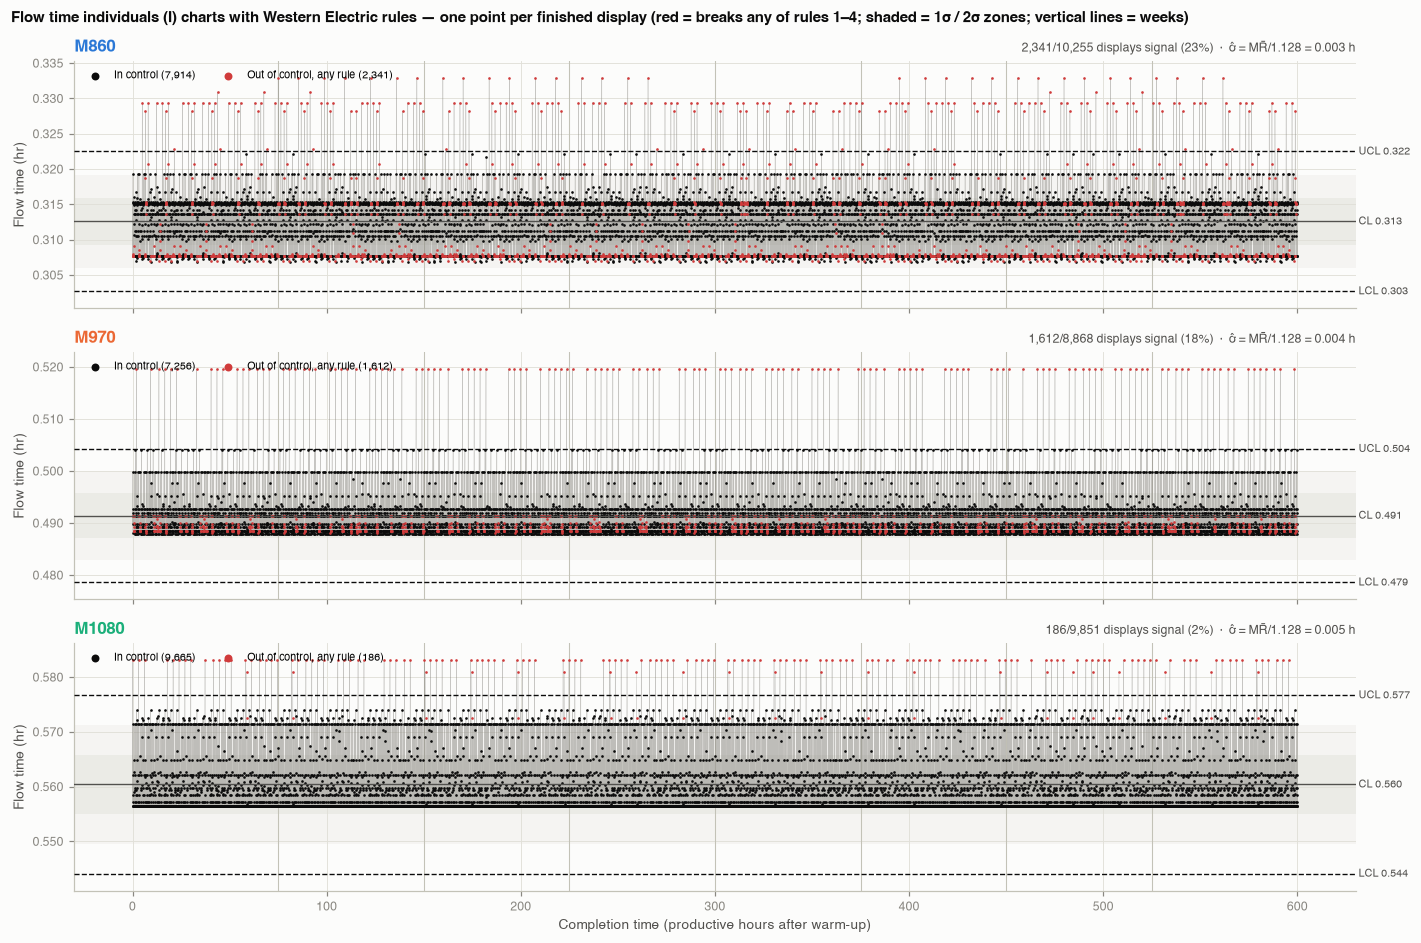

In [9]:
P.plot_flow_time_spc(res_clean, zoom=True)  # linear axis, zoomed to the data; plt.show()
display(flow_summary(res_clean))

## 4) No scrap, Still maintenance and changeovers

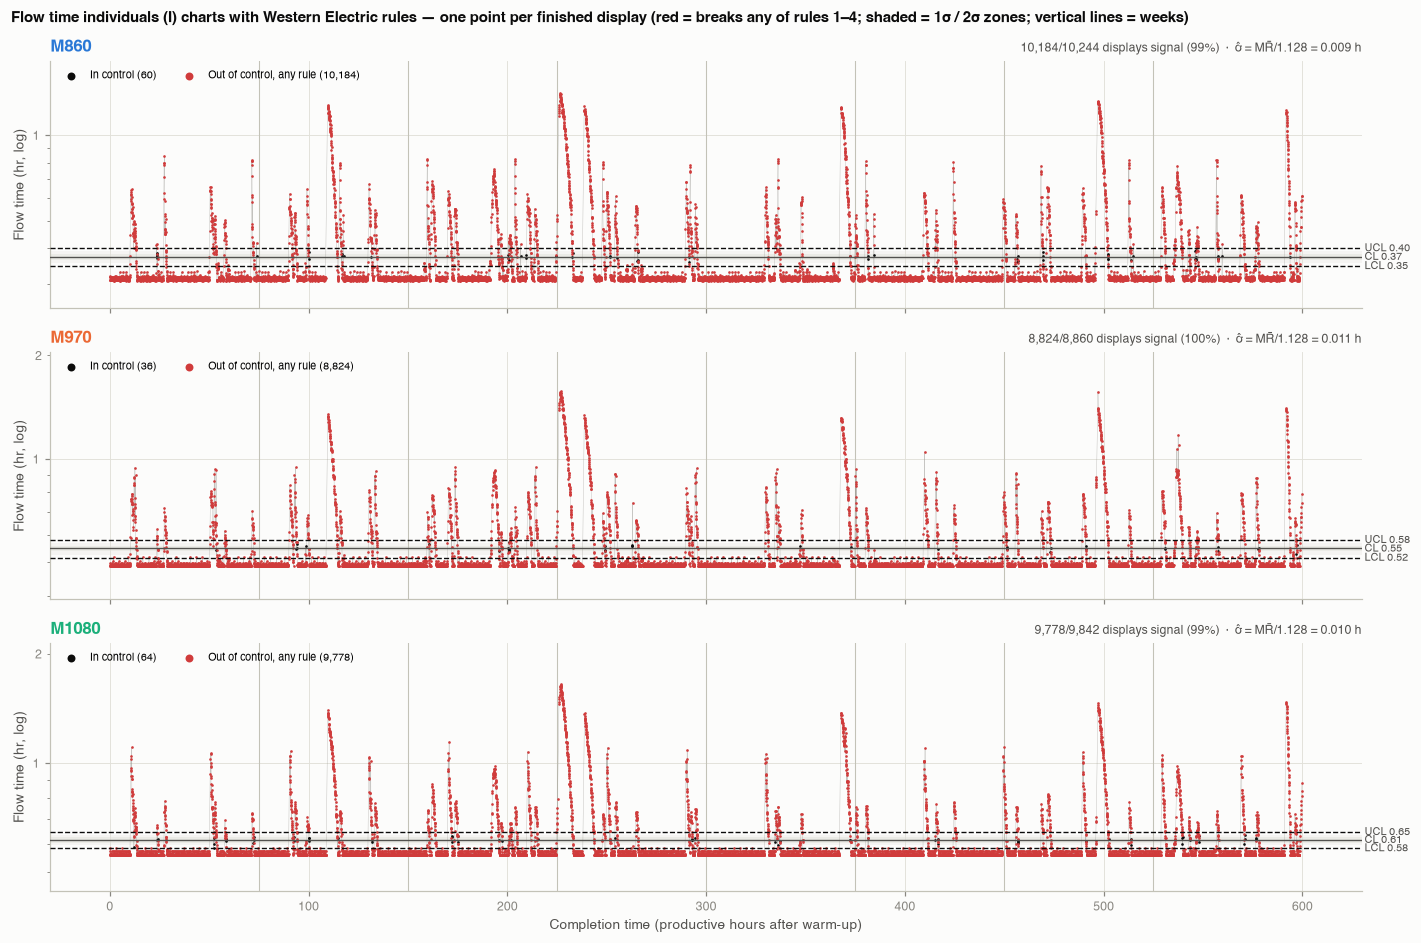

,count,mean,std,min,50%,90%,99%,max
Model,,,,,,,,
M860,10244.0,0.373,0.156,0.307,0.315,0.521,1.178,1.408
M970,8860.0,0.549,0.148,0.488,0.491,0.697,1.276,1.575
M1080,9842.0,0.614,0.144,0.557,0.560,0.739,1.320,1.647


In [10]:
P.plot_flow_time_spc(res_noscrap); plt.show()
display(flow_summary(res_noscrap))

## All four cases (seeds 1–3)

In [11]:
# cases = {
#     "Base (changeovers + maintenance)": {},
#     "No maintenance": dict(failures_on=False, pm_on=False),
#     "No changeovers": dict(setups_on=False),
#     "No changeovers, no maintenance": dict(setups_on=False, failures_on=False, pm_on=False),
#     "No scrap, no changeovers, no maintenance": dict(scrap_scale=0, setups_on=False, failures_on=False, pm_on=False),
#     "No scrap (changeovers + maintenance on)": dict(scrap_scale=0),
# }
# rows = []
# for label, kw in cases.items():
#     for seed in (1, 2, 3):
#         r = run(get_scenario(YEAR, **{**base, **kw}, seed=seed, keep_logs=False))
#         f = r.flow["Flow time (hr)"]
#         rows.append({"Case": label, "Throughput/wk": r.kpis["Throughput|Total per week"],
#                      "Avg flow (hr)": f.mean(), "P90 flow (hr)": f.quantile(.9), "P99 flow (hr)": f.quantile(.99),
#                      "Max flow (hr)": f.max(), "Avg WIP": r.kpis["WIP|Average WIP (parts)"]})
# display(pd.DataFrame(rows).groupby("Case", sort=False).mean().round(2))